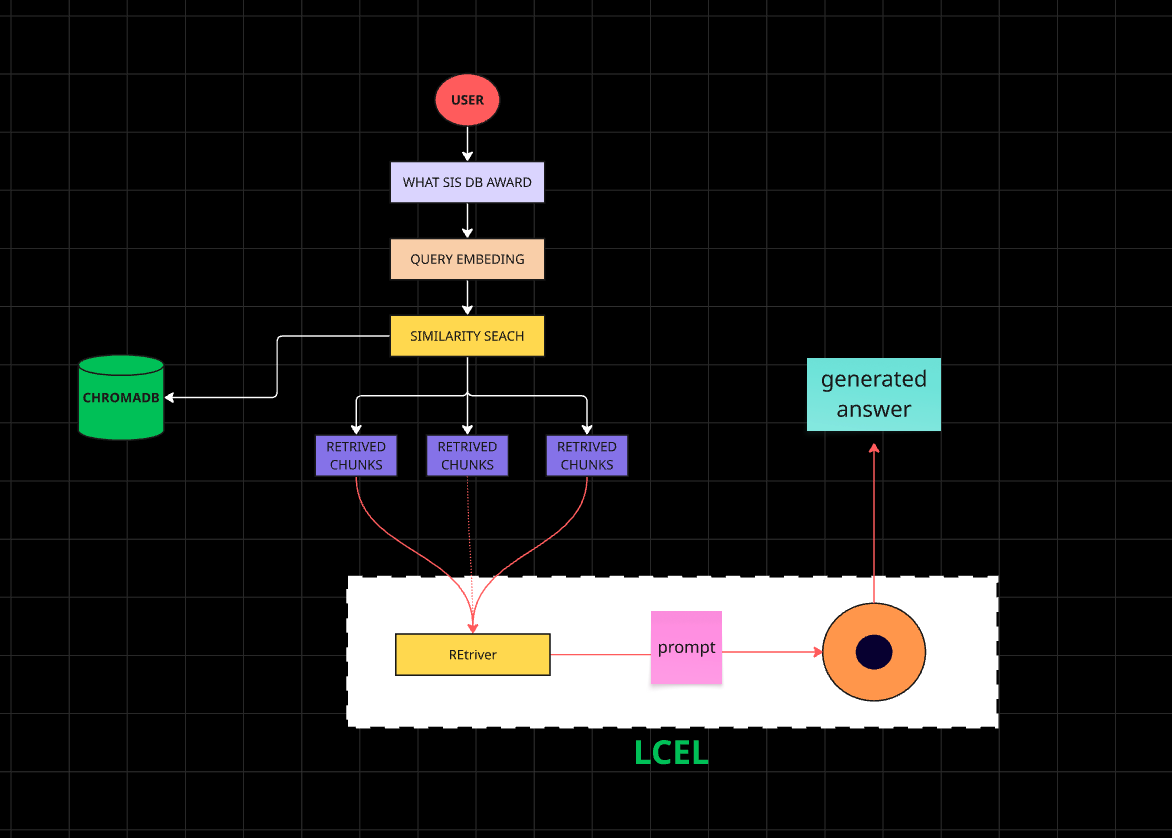

In [3]:
# Libraries import
import os 
from dotenv import load_dotenv
load_dotenv(override=True)

## text loading # directory load #embediings # text splitting
from langchain_community.document_loaders import DirectoryLoader, TextLoader
from langchain_text_splitters import RecursiveCharacterTextSplitter
from langchain_huggingface import HuggingFaceEmbeddings
from langchain_openai import OpenAIEmbeddings

from langchain_openai import ChatOpenAI

# vector store
from langchain_community.vectorstores import FAISS

#prompt template and LCEL
from langchain_core.prompts import ChatPromptTemplate
from langchain_core.runnables import RunnablePassthrough
from langchain_core.output_parsers import StrOutputParser

/var/folders/m8/jv_qd8md6_n84v8zcshwvjm40000gn/T/ipykernel_60775/3636336566.py:7: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import DirectoryLoader, TextLoader
/Volumes/ManojData/github/ITK-FREE-GENAI-SERIES-NOTES/.ITK-FREE-GENAI-SERIES-NOTES/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [4]:
# TO ENABLE MONITORING THE AI WORKLOADS WILL BE USING https://smith.langchain.com/
os.environ["LANGCHAIN_TRACING_V2"] = "true"
os.environ["LANGCHAIN_ENDPOINT"] = "https://api.smith.langchain.com"
os.environ["LANGCHAIN_PROJECT"] = os.getenv("LANGSMITH_PROJECT", "ITK-GENAI")

In [5]:
langsmith_key = os.getenv("LANGSMITH_API_KEY")
if langsmith_key:
    os.environ["LANGCHAIN_API_KEY"] = langsmith_key

In [6]:
os.environ["OPENAI_API_KEY"] = os.getenv("OPENAI_API_KEY")

In [7]:
# Loding steps:
from docx import document


dir_loader = DirectoryLoader(
    "data",
    glob = "*.txt", # pattern that matches the files
    loader_cls=TextLoader,
    loader_kwargs={
        'encoding':'utf-8'
    },
)

documents = dir_loader.load()
print(f"Total document loaded: {len(documents)}")
documents[0]

Total document loaded: 4


Document(metadata={'source': 'data/python.txt'}, page_content='Python is a high-level, interpreted, \ngeneral-purpose programming language known for its simple syntax and readability. \nIt is widely used in software development, automation, data science, artificial intelligence, \nmachine learning, web development, and DevOps. Python provides many built-in libraries and has a large ecosystem of third-party packages. Frameworks such as FastAPI, Flask, and Django help developers build web applications and APIs. Python is also popular in automation because developers can easily write scripts for managing infrastructure, processing files, interacting with APIs, and performing repetitive tasks. Its simplicity and versatility make Python one of the most widely used programming languages in modern technology.')

In [8]:
# Stage 2: Document Splitting

text_splitter = RecursiveCharacterTextSplitter(
    chunk_size = 500,
    chunk_overlap = 50,
    length_function = len,
    separators= [" "]
)

chunks = text_splitter.split_documents(documents)
print(f"created {len(chunks)} chunks from {len(documents)} documents")

created 108 chunks from 4 documents


In [9]:
print("content: ")
print(chunks[0].page_content)

print("Metadata: ")
print(chunks[0].metadata)

content: 
Python is a high-level, interpreted, 
general-purpose programming language known for its simple syntax and readability. 
It is widely used in software development, automation, data science, artificial intelligence, 
machine learning, web development, and DevOps. Python provides many built-in libraries and has a large ecosystem of third-party packages. Frameworks such as FastAPI, Flask, and Django help developers build web applications and APIs. Python is also popular in automation because
Metadata: 
{'source': 'data/python.txt'}


In [10]:
# stage-3 embeddings
embeddings = OpenAIEmbeddings(
    model = "text-embedding-3-small"
)

FAISS provided by FACEBOOK

Introduction to RAG (Retrieval-Augmented Generation) RAG combines the power of retrieval systems with generative AI models. Instead of relying solely on the model's training data, RAG:

Retrieves relevant documents from a knowledge base
Uses these documents as context for the LLM
Generates responses based on both the retrieved context and the model's knowledge
FAISS
https://github.com/facebookresearch/faiss

FAISS is a library for efficient similarity search and clustering of dense vectors.

Key advantages:

- Extremely fast similarity search
- Memory efficient
- Supports GPU acceleration
- Can handle millions of vectors
- How it works:

Indexes vectors for fast nearest neighbor search
Returns most similar vectors based on distance metrics

In [11]:
vector_store = FAISS.from_documents(
    documents=chunks,
    embedding=embeddings,
)

In [12]:
vector_store.save_local("faiss_index")

In [13]:
query = "What is the Dadasaheb Phalke Award?"

similar_docs = vector_store.similarity_search(
    query,
    k=3
)

similar_docs

[Document(id='5772733a-84e5-49dc-a475-919511d80a60', metadata={'source': 'data/award.txt'}, page_content="for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.\n\n## What is the Dadasaheb Phalke Award?\n\nThe Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.\n\nThe award recognizes outstanding"),
 Document(id='6c0decd4-f284-41f1-9928-baf297a25d05', metadata={'source': 'data/award.txt'}, page_content="of Indian cinema.\n\nAnant Nag has been a part of that landscape for more than five decades.\n\n## Conclusion\n\nThe Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant Nag for his outstanding cont

In [14]:
similar_docs[0].page_content

"for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.\n\n## What is the Dadasaheb Phalke Award?\n\nThe Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.\n\nThe award recognizes outstanding"

In [15]:
query = "What is the Dadasaheb Phalke Award?"

result_score=vector_store.similarity_search_with_score(
    query,
    k=3
)

result_score

[(Document(id='5772733a-84e5-49dc-a475-919511d80a60', metadata={'source': 'data/award.txt'}, page_content="for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.\n\n## What is the Dadasaheb Phalke Award?\n\nThe Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.\n\nThe award recognizes outstanding"),
  np.float32(0.46133924)),
 (Document(id='6c0decd4-f284-41f1-9928-baf297a25d05', metadata={'source': 'data/award.txt'}, page_content="of Indian cinema.\n\nAnant Nag has been a part of that landscape for more than five decades.\n\n## Conclusion\n\nThe Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant

In [16]:
print(result_score)

[(Document(id='5772733a-84e5-49dc-a475-919511d80a60', metadata={'source': 'data/award.txt'}, page_content="for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.\n\n## What is the Dadasaheb Phalke Award?\n\nThe Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.\n\nThe award recognizes outstanding"), np.float32(0.46133924)), (Document(id='6c0decd4-f284-41f1-9928-baf297a25d05', metadata={'source': 'data/award.txt'}, page_content="of Indian cinema.\n\nAnant Nag has been a part of that landscape for more than five decades.\n\n## Conclusion\n\nThe Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant Na

In [15]:
for doc,score in result_score:
    print("\nScore:", score)
    print(doc.page_content[:300]) 


Score: 0.4616252
for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.

## What is the Dadasaheb Phalke Award?

The Dadasaheb Phalke Award was institu

Score: 0.87372607
of Indian cinema.

Anant Nag has been a part of that landscape for more than five decades.

## Conclusion

The Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant Nag for his outstanding contribution to Ind

Score: 0.8804796
# Anant Nag and the Dadasaheb Phalke Award: A Golden Recognition for Kannada Cinema

Indian cinema is not just about entertainment. It is a reflection of our culture, language, emotions, traditions and society. Over the decades, many artists have dedicated their lives to enriching Indian cinema. Amo


In [17]:
#stage-6 creating retriver
retriever = vector_store.as_retriever(
    search_kwargs={
        "k": 3
    }
)

In [18]:
retriever

VectorStoreRetriever(tags=['FAISS', 'OpenAIEmbeddings'], vectorstore=<langchain_community.vectorstores.faiss.FAISS object at 0x14ab657c0>, search_kwargs={'k': 3})

In [19]:
query = "What is the Dadasaheb Phalke Award?"
retrived_docs = retriever.invoke(query)
retrived_docs

[Document(id='5772733a-84e5-49dc-a475-919511d80a60', metadata={'source': 'data/award.txt'}, page_content="for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.\n\n## What is the Dadasaheb Phalke Award?\n\nThe Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.\n\nThe award recognizes outstanding"),
 Document(id='6c0decd4-f284-41f1-9928-baf297a25d05', metadata={'source': 'data/award.txt'}, page_content="of Indian cinema.\n\nAnant Nag has been a part of that landscape for more than five decades.\n\n## Conclusion\n\nThe Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant Nag for his outstanding cont

In [20]:
for i, doc in enumerate(retrived_docs, start=1):
    print(f"\n--- Retrieved Document {i} ---")
    print(doc.page_content)
    print("Metadata:", doc.metadata)


--- Retrieved Document 1 ---
for the year 2024, India's highest honour in the field of cinema. President Droupadi Murmu presented the award to him at the 72nd National Film Awards ceremony held at Ekta Nagar, Kevadia, Gujarat, on September 22, 2026.

## What is the Dadasaheb Phalke Award?

The Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913.

The award recognizes outstanding
Metadata: {'source': 'data/award.txt'}

--- Retrieved Document 2 ---
of Indian cinema.

Anant Nag has been a part of that landscape for more than five decades.

## Conclusion

The Dadasaheb Phalke Award is one of the most significant recognitions an Indian film artist can receive. In 2026, this honour was presented to Anant Nag for his outstanding contribution to Indian cinema.

For Karnataka, Kannada cinema and millions of his admirers, this is a memorable moment.

From theatr

In [20]:
llm = ChatOpenAI(
    model = 'gpt-4o-mini',
    temperature=0
)

In [21]:

response = llm.invoke("hi")

In [22]:
response.content

'Hello! How can I assist you today?'

In [23]:
#STAGE-8 CREATING THE RAG TEMPLATE
custom_prompt = ChatPromptTemplate.from_template("""
You are a helpful assistant.

Answer the question using ONLY the provided context.

If the answer cannot be found in the context, say:
"I don't know based on the provided documents."

Context:
{context}

Question:
{question}

Answer:
""")

In [24]:
# STAGE-9 BUILDING COMPLETE RAG

ragchain = (
    {
        "context": retriever,
        "question": RunnablePassthrough()
    }
    | custom_prompt
    | llm
    | StrOutputParser()
)

In [25]:
# TESTING PHASE:
question = "What is the Dadasaheb Phalke Award?"

answer = ragchain.invoke(question)

print(answer)


The Dadasaheb Phalke Award was instituted by the Government of India in 1969 to commemorate Dadasaheb Phalke, who directed India's first full-length feature film, Raja Harishchandra, in 1913. The award recognizes outstanding contributions to Indian cinema.


In [26]:
question = "can you sing song for me becuse its 1:00AM"

answer = ragchain.invoke(question)

print(answer)

I don't know based on the provided documents.


# NEW DOCMENT DATA INGESTION

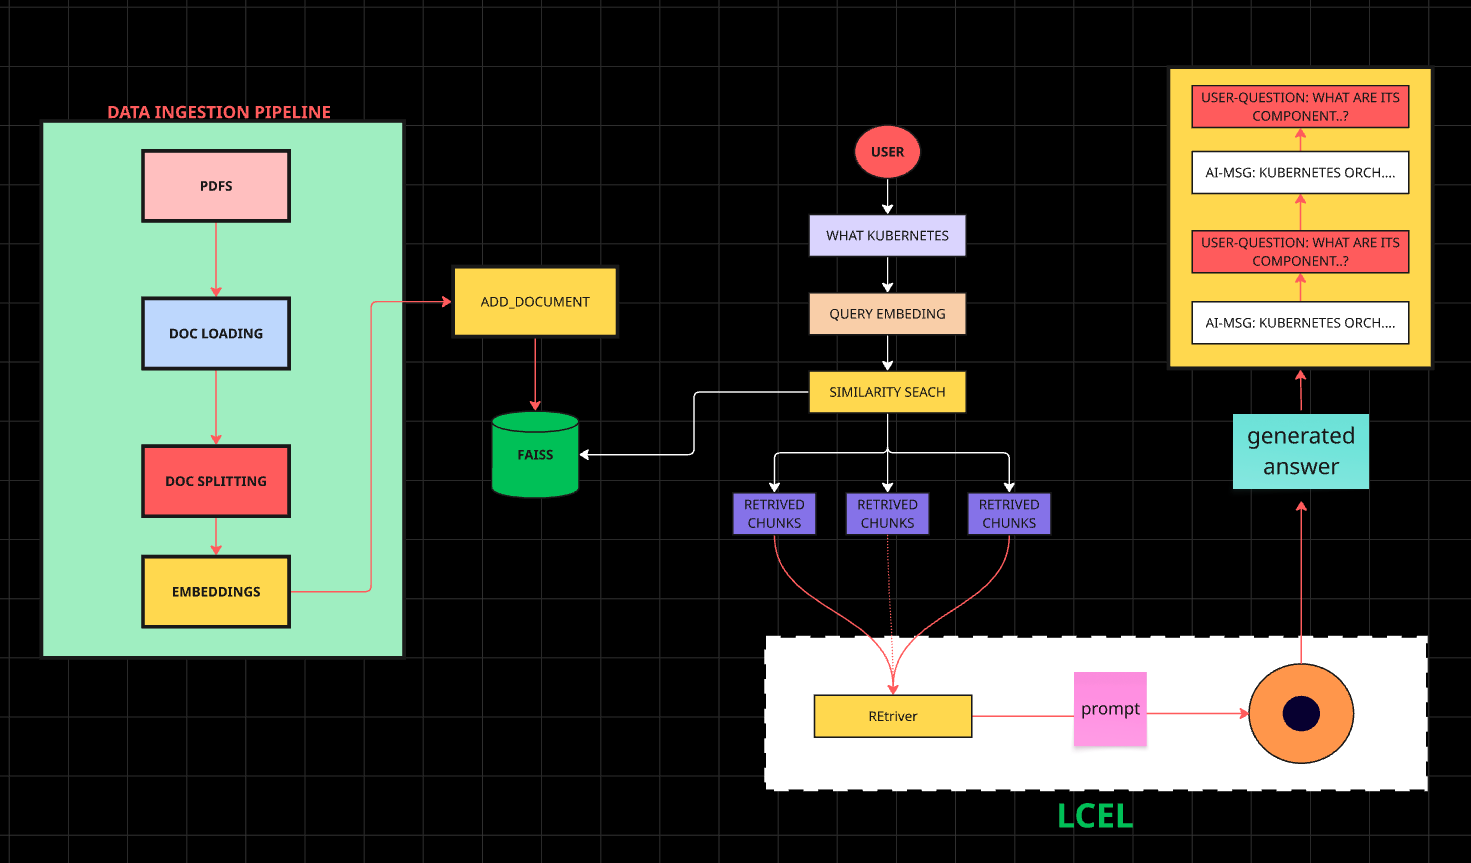

In [27]:
from langchain_community.document_loaders import (
    DirectoryLoader,
    PyMuPDFLoader
)

from langchain_text_splitters import RecursiveCharacterTextSplitter

In [28]:
from pathlib import Path
# Check whether your folder contains PDFs
folder_path = Path(
    "/Volumes/ManojData/github/ITK-FREE-GENAI-SERIES-NOTES/DAY-18/New_docs"
)

pdf_files = list(folder_path.rglob("*.pdf"))

print("PDF files found:", len(pdf_files))

for pdf in pdf_files:
    print(pdf.name)

# Load the new documents

loader = DirectoryLoader(
    str(folder_path),
    glob="**/*.[pP][dD][fF]",
    loader_cls=PyMuPDFLoader,
    show_progress=True,
    silent_errors=False
)

new_documents = loader.load()

print("Total pages loaded:", len(new_documents))

for doc in new_documents[:2]:
    print(doc.metadata)
    print(doc.page_content[:200])

PDF files found: 2
fp_monitoring_2000_frep_09_en.pdf
HospitalEpisodeStatistics.pdf


  0%|          | 0/2 [00:00<?, ?it/s]

100%|██████████| 2/2 [00:00<00:00,  3.64it/s]

Total pages loaded: 254
{'producer': 'PDF CoDe 1.00.20030707 (c) 2002-2003 European Commission', 'creator': 'Dept of Health', 'creationdate': '2003-10-13T08:24:32+00:00', 'source': '/Volumes/ManojData/github/ITK-FREE-GENAI-SERIES-NOTES/DAY-18/New_docs/fp_monitoring_2000_frep_09_en.pdf', 'file_path': '/Volumes/ManojData/github/ITK-FREE-GENAI-SERIES-NOTES/DAY-18/New_docs/fp_monitoring_2000_frep_09_en.pdf', 'total_pages': 239, 'format': 'PDF 1.4', 'title': 'The Hospital Data Project', 'author': 'Hugh Magee', 'subject': 'Final report', 'keywords': 'European Commission, Public health, health monitoring, Hospital, Data, Project', 'moddate': '2003-10-13T10:55:10+02:00', 'trapped': '', 'modDate': "D:20031013105510+02'00'", 'creationDate': 'D:20031013082432Z', 'page': 0}
Agreement No. SI2.304597 
Hospital Data Project 
 
           
 
 
 
 
 
 
HOSPITAL DATA PROJECT 
 
FINAL REPORT 
 
June 2003
{'producer': 'PDF CoDe 1.00.20030707 (c) 2002-2003 European Commission', 'creator': 'Dept of Health',

In [29]:
text_splitter = RecursiveCharacterTextSplitter(
    chunk_size=1000,
    chunk_overlap=100
)

new_chunks = text_splitter.split_documents(new_documents)

print("New chunks created:", len(new_chunks))

New chunks created: 657


In [30]:
vector_store = FAISS.from_documents(
    documents=chunks,
    embedding=embeddings,
)

In [31]:
if new_chunks:
    vector_store.add_documents(new_chunks)
    print(f"ADDED new chunks,,,..{len(new_chunks)}")
else:
    print("NO chunks are available to add..")

ADDED new chunks,,,..657


In [32]:
question = "What information is available in the newly added documents?"

results = vector_store.similarity_search(question,k=3)

for doc in results:
    print(doc.page_content)
    print(doc.metadata)
    print("---"*50)

Agreement No. SI2.304597 
Annex 13 
 
230
Section 1 continued 
Feedback on Data 
 
Name of Country __________________ 
Please insert the name of the country to which the comments refer 
  
Have additional data validation checks 
have been carried out? 
 
    Yes            No 
 
If yes, please elaborate on these 
additional data validation checks and any 
errors/problems that arose below. 
 
Suggested Solutions 
(e.g., submit new data file, ensure 
comment is included in meta data) 
 
 
 
Please identify solutions in the box 
below 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
 
Please insert additional pages if necessary
{'producer': 'PDF CoDe 1.00.20030707 (c) 2002-2003 European Commission', 'creator': 'Dept of Health', 'creationdate': '2003-10-13T08:24:32+00:00', 'source': '/Volumes/ManojData/github/ITK-FREE-GENAI-SERIES-NOTES/DAY-18/New_docs/fp_monitoring_2000_frep_09_en.pdf', 'file_path': '/Volumes/ManojData/github/ITK-FREE-GENAI-SERIES-NOTES/DAY

In [33]:
ragchain = (
    {
        "context": retriever,
        "question": RunnablePassthrough()
    }
    | custom_prompt
    | llm
    | StrOutputParser()
)

In [34]:
question = "what is kubernetes..?"

result =ragchain.invoke(question)

result

'Kubernetes is an open-source container orchestration platform. It automates the deployment, scaling, networking, and management of containerized applications.'

In [35]:
question = "what are its components"

result =ragchain.invoke(question)

result

'The main control plane components are kube-apiserver, etcd, kube-scheduler, and kube-controller-manager. Cloud environments may also use cloud-controller-manager.'

In [36]:
question = "explain about above"

result =ragchain.invoke(question)

result

"I don't know based on the provided documents."

# ADDING CONVERSATION:
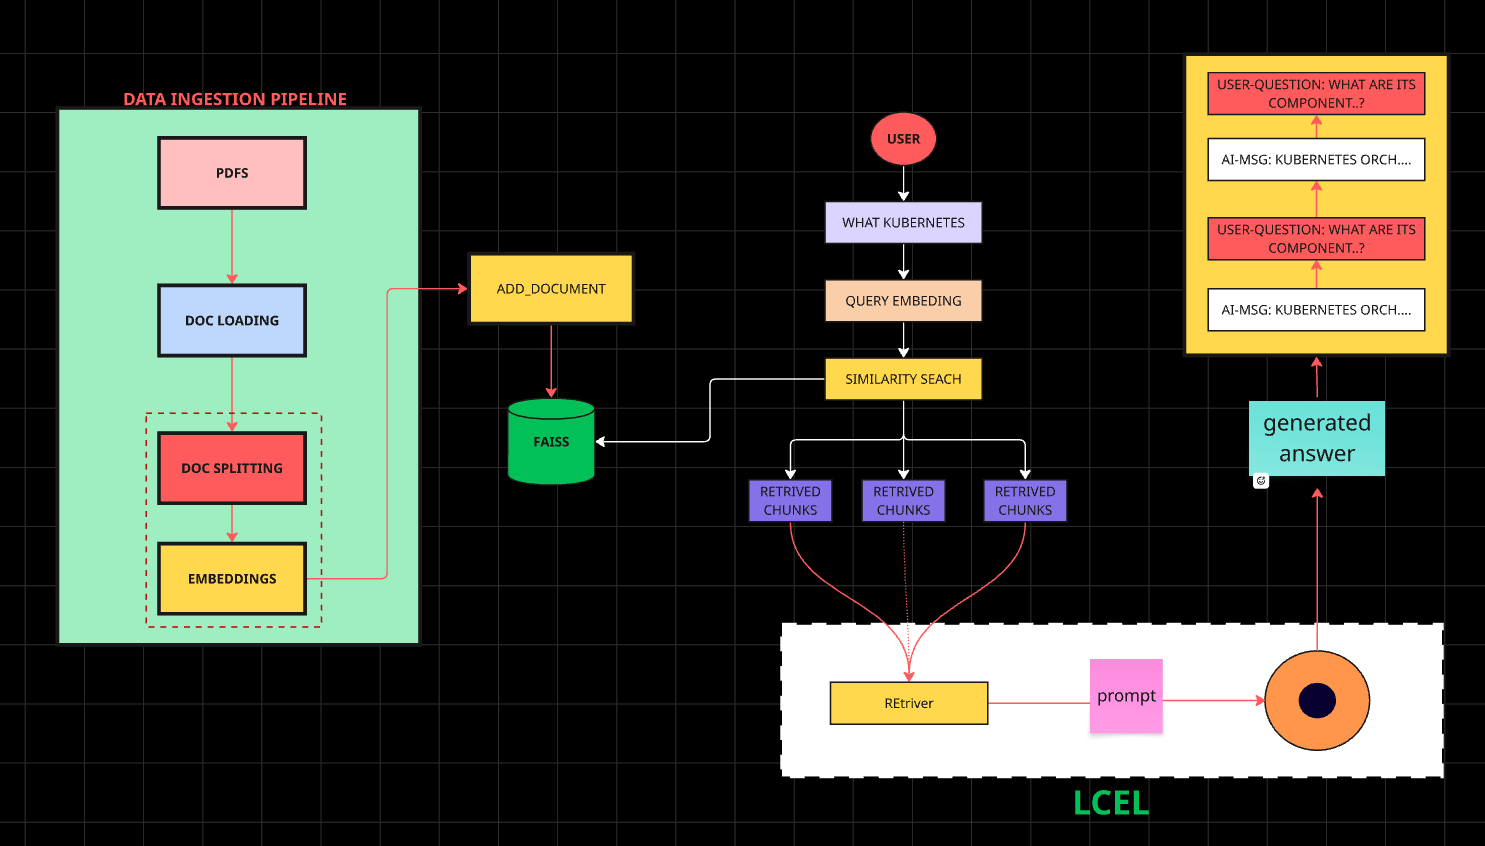

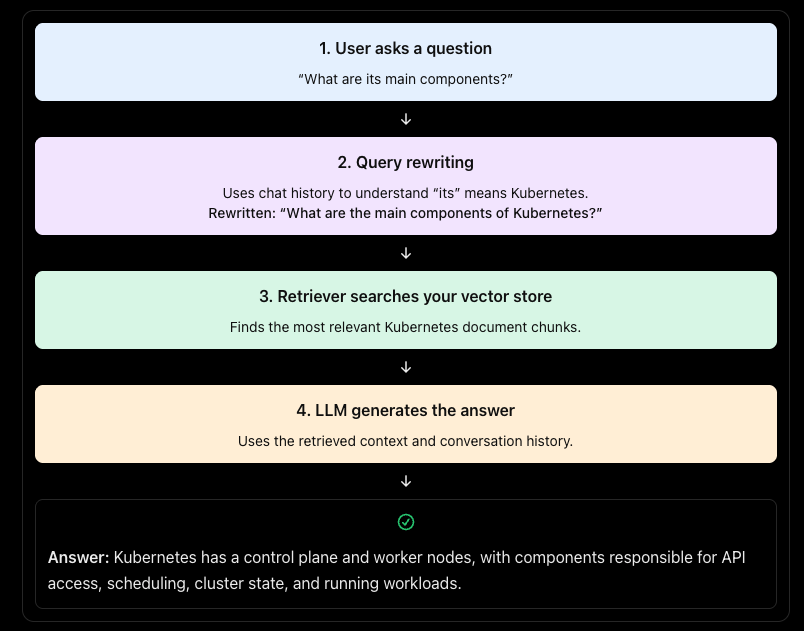

In [37]:
from langchain_core.prompts import (
    ChatPromptTemplate,
    MessagesPlaceholder
)

from langchain_core.messages import (
    HumanMessage,
    AIMessage
)

from langchain_core.output_parsers import StrOutputParser
from langchain_core.runnables import RunnablePassthrough
from langchain_openai import ChatOpenAI

# What does each import do?
Component	Purpose
- ChatPromptTemplate:	Creates instructions and message templates for the LLM.
- MessagesPlaceholder:	Inserts previous conversation messages into a prompt.
- HumanMessage:	Represents a message from the user.
- AIMessage:	Represents a message from the AI.
- StrOutputParser:	Converts the model's output into a plain string.
- RunnablePassthrough:	Passes input data forward and lets us add extra fields.
- ChatOpenAI:	Connects to an OpenAI chat model.

Think of these as the building blocks used to assemble your RAG workflow.

In [38]:
llm = ChatOpenAI(
    model="gpt-4o-mini",
    temperature=0
)

retriever = vector_store.as_retriever(
    search_kwargs={"k": 3}
)

- The LLM generates answers and rewrites follow-up questions. temperature=0 generally makes its responses more consistent.
- The retriever searches your existing vector store for relevant document chunks. k=3 means it requests the three most relevant results for each search.
- For example, if the vector store contains your Kubernetes Q&A text, a question about Deployments should retrieve chunks discussing Deployments.
- You do not need to create a new vector store here. The variable vector_store must already exist in your notebook.

In [39]:
rewrite_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "Rewrite the latest question as a standalone question "
        "using the conversation history. Do not answer it."
    ),
    MessagesPlaceholder("chat_history"),
    ("human", "{input}")
])

rewrite_chain = (
    rewrite_prompt
    | llm
    | StrOutputParser()
)

Imagine the history is:
- User: “What is Kubernetes?”
- AI: “Kubernetes is a container orchestration platform.”
- User: “What are its main components?”
The rewriting chain receives the previous messages and the latest question. It can turn the ambiguous question into:
What are the main components of Kubernetes?

Notice the pipe symbol |. In LangChain Expression Language (LCEL), it connects components into a sequence:
Prompt → LLM → String output
The rewriting chain does not retrieve documents or answer the user's question. Its job is to produce a clearer search query.

# Make retrieval history-aware

In [40]:
def retrieve_with_history(inputs):
    if inputs.get("chat_history"):
        standalone_question = rewrite_chain.invoke(inputs)
    else:
        standalone_question = inputs["input"]

    return retriever.invoke(standalone_question)

history_aware_retriever = retrieve_with_history

1. It receives the current question and conversation history.

2. If history exists, it rewrites the question.

3. If no history exists, it uses the original question.

4. It sends the resulting question to the retriever.

5. The retriever returns relevant documents from your vector store.

In [41]:
qa_prompt = ChatPromptTemplate.from_messages([
    (
        "system",
        "Answer using the retrieved context. If the answer is "
        "not in the context, say you do not have enough information.\n\n"
        "Context:\n{context}"
    ),
    MessagesPlaceholder("chat_history"),
    ("human", "{input}")
])

def format_docs(docs):
    return "\n\n".join(
        doc.page_content for doc in docs
    )

# Connect retrieval and answer generation

In [42]:
conversational_rag_chain = (
    RunnablePassthrough.assign(
        context=lambda inputs: format_docs(
            retrieve_with_history(inputs)
        )
    )
    | qa_prompt
    | llm
    | StrOutputParser()
)

## RunnablePassthrough.assign(...) preserves the incoming dictionary containing input and chat_history, then adds a new field called context.

That context is produced by:
1. Retrieving relevant documents.
2. Formatting those documents into a string.
Then the chain runs the answer prompt, sends it to the LLM, and returns a plain-text answer.


## The complete sequence is:
Input + History → Retrieve documents → Add Context → Build Prompt → LLM → Answer


The chain uses your history-aware retrieval function for searching, while the answer prompt also receives the original conversation history.

In [43]:
chat_history = []

question = "What is Kubernetes?"

answer = conversational_rag_chain.invoke({
    "input": question,
    "chat_history": chat_history
})

print(answer)

chat_history.extend([
    HumanMessage(content=question),
    AIMessage(content=answer)
])

Kubernetes is an open-source container orchestration platform. It automates the deployment, scaling, networking, and management of containerized applications.


In [44]:
question = "What are its main components?"

answer = conversational_rag_chain.invoke({
    "input": question,
    "chat_history": chat_history
})

print(answer)

chat_history.extend([
    HumanMessage(content=question),
    AIMessage(content=answer)
])

The main components of Kubernetes include the control plane components: kube-apiserver, etcd, kube-scheduler, and kube-controller-manager. Additionally, cloud environments may also use cloud-controller-manager.


In [45]:
def ask(question):
    global chat_history

    answer = conversational_rag_chain.invoke({
        "input": question,
        "chat_history": chat_history
    })

    print("Question:", question)
    print("Answer:", answer)

    chat_history.extend([
        HumanMessage(content=question),
        AIMessage(content=answer)
    ])

    return answer

In [46]:
ask("what is kubernetes..?")

Question: what is kubernetes..?
Answer: Kubernetes is an open-source container orchestration platform that automates the deployment, scaling, networking, and management of containerized applications.


'Kubernetes is an open-source container orchestration platform that automates the deployment, scaling, networking, and management of containerized applications.'

In [47]:
ask("what are its components..?")

Question: what are its components..?
Answer: The main components of Kubernetes include the control plane components: kube-apiserver, etcd, kube-scheduler, and kube-controller-manager. Additionally, cloud environments may also use cloud-controller-manager.


'The main components of Kubernetes include the control plane components: kube-apiserver, etcd, kube-scheduler, and kube-controller-manager. Additionally, cloud environments may also use cloud-controller-manager.'

In [48]:
ask("what does scheduler do..?")

Question: what does scheduler do..?
Answer: The scheduler chooses a suitable node for a Pod that has not yet been assigned to one. It helps place workloads appropriately and supports capacity planning. Correct requests improve the behavior of resource-based autoscaling.


'The scheduler chooses a suitable node for a Pod that has not yet been assigned to one. It helps place workloads appropriately and supports capacity planning. Correct requests improve the behavior of resource-based autoscaling.'

In [49]:
ask("How can it affect application availability?")

Question: How can it affect application availability?
Answer: The scheduler can affect application availability by ensuring that Pods are placed on nodes with sufficient resources. If the scheduler does not make optimal placement decisions, it can lead to resource contention, underutilization, or overloading of nodes, which may impair the application's performance and availability.


"The scheduler can affect application availability by ensuring that Pods are placed on nodes with sufficient resources. If the scheduler does not make optimal placement decisions, it can lead to resource contention, underutilization, or overloading of nodes, which may impair the application's performance and availability."